[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jadg1/economic-networks-seminar/blob/main/labs/dean_timing.ipynb)

**Run it in Google Colab, with nothing to install:** click the badge, then run the setup cell below first. On your own computer the setup cell does nothing.

In [ ]:
# Setup for Google Colab: gets the repository's files and the two extra packages.
# On your own computer (with the econ-networks environment) this cell does nothing.
import os, sys
if "google.colab" in sys.modules:
    REPO = "jadg1/economic-networks-seminar"
    if not os.path.exists("/content/economic-networks-seminar"):
        !git clone -q --depth 1 https://github.com/{REPO}.git /content/economic-networks-seminar
    %cd /content/economic-networks-seminar/labs
    %pip install -q pyreadr pyvis
    print("Ready: running from the repository's labs folder.")

# Reaching the dean, with time: how long does it take, and what if people are

only available on certain days?  
Economic Networks, Part 1 (links to Part 2)  

A. Asking in parallel, every day, until it gets through.  
Everyone who knows mentions it to each contact each day, and each  
mention works with that link's daily probability. Nobody forgets, so the  
message eventually reaches the dean; the question is WHEN. This is a  
Markov chain whose state is "who knows so far" (an SI epidemic: SIR with  
no recovery). With 7 people there are only 128 states, so the  
distribution of the dean's arrival day is computed exactly.  

B. Time restrictions: a temporal network.  
Each link only works on certain weekdays (office hours, meetings, the  
dean's diary). A route only works if its meetings happen in the right  
order, so the fastest route can be a strange one. Earliest arrival is a  
day-by-day version of Dijkstra (one conversation per day per message).  

C. Both together: daily probabilities AND weekly schedules, simulated.  
What's the chance the dean hears by Friday, or by the end of next week?  

`Needs: pip install networkx matplotlib numpy`

## Setup

In [1]:
%matplotlib inline

In [2]:
import random
from itertools import product
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

PEOPLE = ["You", "Classmate", "Professor", "Head of dept", "Secretary", "Vice-dean", "Dean"]
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri"]

# Chance a mention gets passed on, on a day the link works (same as dean_reach.py)
P = {
    ("You", "Classmate"): 0.95, ("You", "Professor"): 0.85, ("Classmate", "Professor"): 0.60,
    ("Professor", "Head of dept"): 0.80, ("Professor", "Secretary"): 0.50,
    ("Head of dept", "Secretary"): 0.85, ("Head of dept", "Vice-dean"): 0.70,
    ("Vice-dean", "Dean"): 0.80, ("Secretary", "Dean"): 0.90, ("You", "Secretary"): 0.40,
}

# Weekdays each link can work (0 = Monday ... 4 = Friday). Edit to fit your story.
WHEN = {
    ("You", "Classmate"): [0, 1, 2, 3, 4],
    ("You", "Professor"): [3],               # office hours on Thursday only
    ("Classmate", "Professor"): [1],         # the classmate is the professor's TA on Tuesday
    ("Professor", "Head of dept"): [2],      # department meeting on Wednesday
    ("Professor", "Secretary"): [4],
    ("Head of dept", "Secretary"): [0, 1, 2],  # the head is away Thursday and Friday
    ("Head of dept", "Vice-dean"): [2],      # committee on Wednesday
    ("Vice-dean", "Dean"): [1, 3],
    ("Secretary", "Dean"): [0],              # the weekly diary meeting, Monday
    ("You", "Secretary"): [0, 1, 2, 3, 4],   # a post-it can go any day
}

STRATEGIES = {   # which of your own links you use
    "Post-it to the secretary": ["Secretary"],
    "Ask your professor": ["Professor"],
    "Post-it and ask your professor": ["Secretary", "Professor"],
    "Ask everyone you know": ["Classmate", "Professor", "Secretary"],
}

POS = {"You": (0, 2), "Classmate": (0, 0.4), "Professor": (2, 2), "Head of dept": (4, 1.2),
       "Secretary": (6, 3), "Vice-dean": (6, -0.2), "Dean": (8, 1.6)}
INK, MUTED, LINE, BLUE, CORAL, GREEN, AMBER, VIOLET = ("#1B1F3B", "#8A8FA8", "#C9CCD8", "#2D6CF6",
                                                     "#F2464F", "#12A873", "#E89400", "#7653E8")
COLORS = [CORAL, BLUE, VIOLET, GREEN]


def prob(a, b):
    return P.get((a, b), P.get((b, a)))


def when(a, b):
    return WHEN.get((a, b), WHEN.get((b, a)))


def neighbours(v):
    return [b if a == v else a for a, b in P if v in (a, b)]


def usable(a, b, asks):
    """Your own links only count if you chose to use them."""
    if "You" in (a, b):
        other = b if a == "You" else a
        return other in asks
    return True

## A. Exact: the Markov chain over "who knows" (every day, no schedules)

In [3]:
def arrival_distribution(asks, days=15):
    """P(dean has heard by the end of day t), t = 1..days, computed exactly."""
    idx = {p: i for i, p in enumerate(PEOPLE)}
    dist = {frozenset(["You"]): 1.0}
    heard_by = []
    for _ in range(days):
        new = {}
        for knows, w in dist.items():
            if "Dean" in knows:
                new[knows] = new.get(knows, 0) + w
                continue
            # each person who doesn't know yet: chance at least one informed contact tells them
            chance = {}
            for v in PEOPLE:
                if v in knows:
                    continue
                miss = 1.0
                for u in neighbours(v):
                    if u in knows and usable(u, v, asks):
                        miss *= 1 - prob(u, v)
                if miss < 1:
                    chance[v] = 1 - miss
            cands = list(chance)
            for outcome in product([True, False], repeat=len(cands)):
                pw = np.prod([chance[c] if o else 1 - chance[c] for c, o in zip(cands, outcome)]) if cands else 1.0
                nxt = knows | {c for c, o in zip(cands, outcome) if o}
                new[nxt] = new.get(nxt, 0) + w * pw
        dist = new
        heard_by.append(sum(w for k, w in dist.items() if "Dean" in k))
    return heard_by


def expected_days(heard_by):
    """Expected arrival day, from P(arrived by day t) (tail is negligible here)."""
    return sum(1 - h for h in [0] + heard_by[:-1])

## B. Temporal network: earliest arrival with weekly schedules

In [4]:
def earliest_arrival(asks=None, start_day=0, horizon=21):
    """Day-by-day earliest arrival (no failures). Day 0 = Monday of week 1.
    Each day, a link that works that weekday passes the message from someone
    who knew BEFORE that day. Returns arrival day and predecessor per person."""
    asks = asks if asks is not None else neighbours("You")
    arrival, before = {"You": start_day - 1}, {}
    for d in range(start_day, start_day + horizon):
        if d % 7 > 4:
            continue                                   # weekend
        today = {}
        for (a, b), days in WHEN.items():
            if d % 7 not in days or not usable(a, b, asks):
                continue
            for u, v in ((a, b), (b, a)):
                if u in arrival and arrival[u] < d and v not in arrival and v not in today:
                    today[v] = u
        for v, u in today.items():
            arrival[v], before[v] = d, u
    return arrival, before


def route_to(before, target="Dean"):
    path = [target]
    while path[-1] in before:
        path.append(before[path[-1]])
    return path[::-1]


def follow_route(route, start_day=0, horizon=35):
    """Arrival day if the message must follow this exact route, waiting for each meeting."""
    d = start_day - 1
    for a, b in zip(route, route[1:]):
        d += 1
        while d % 7 > 4 or d % 7 not in when(a, b):
            d += 1
            if d > start_day + horizon:
                return None
    return d


def day_name(d):
    if d is None:
        return "never (within 5 weeks)"
    week = d // 7 + 1
    return f"{DAYS[d % 7]} of week {week}"

## C. Both together: schedules AND probabilities, simulated

In [5]:
def simulate(asks, deadline_days, runs=20000, seed=1):
    """Chance the dean has heard by each deadline (in days from Monday of week 1)."""
    rng = random.Random(seed)
    hits = {d: 0 for d in deadline_days}
    last = max(deadline_days)
    for _ in range(runs):
        knows = {"You": -1}
        for d in range(last + 1):
            if d % 7 > 4:
                continue
            new = []
            for (a, b), days in WHEN.items():
                if d % 7 not in days or not usable(a, b, asks):
                    continue
                for u, v in ((a, b), (b, a)):
                    if u in knows and knows[u] < d and v not in knows and rng.random() < P[(a, b)]:
                        new.append(v)
            for v in new:
                knows.setdefault(v, d)
            if "Dean" in knows:
                break
        for dl in deadline_days:
            if "Dean" in knows and knows["Dean"] <= dl:
                hits[dl] += 1
    return {dl: h / runs for dl, h in hits.items()}

## Pictures

In [6]:
def draw_timing_curves(curves, path=None):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    styles = ["-", "-", "-", (0, (4, 3))]   # the last two coincide here, so one is dashed
    widths = [2.2, 2.2, 4.5, 2.2]
    for (name, h), col, ls, lw in zip(curves.items(), COLORS, styles, widths):
        h = h[:10]
        ax.plot(range(1, len(h) + 1), h, marker="o", ms=3.5, lw=lw, ls=ls, color=col, label=name)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("days of asking")
    ax.set_ylabel("chance the dean has heard")
    ax.set_title("Keep asking and it always arrives; the strategy decides how fast",
                 loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    return fig


def draw_temporal(arrival, fastest, cheapest, path=None):
    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    fast = {frozenset(e) for e in zip(fastest, fastest[1:])}
    cheap = {frozenset(e) for e in zip(cheapest, cheapest[1:])}
    for (a, b), days in WHEN.items():
        (xa, ya), (xb, yb) = POS[a], POS[b]
        e = frozenset((a, b))
        col, lw = (GREEN, 5) if e in fast else ((BLUE, 3.5) if e in cheap else (LINE, 2.5))
        ax.plot([xa, xb], [ya, yb], color=col, lw=lw, zorder=1, solid_capstyle="round")
        label = "every day" if len(days) == 5 else ", ".join(DAYS[d] for d in days)
        ax.text((xa + xb) / 2, (ya + yb) / 2, label, ha="center", va="center", fontsize=8.5,
                color=INK, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none"), zorder=3)
    for n, (x, y) in POS.items():
        ax.text(x, y, n, ha="center", va="center", fontsize=10, fontweight="bold", color="white",
                bbox=dict(boxstyle="round,pad=0.45", lw=0, fc=INK if n in ("You", "Dean") else MUTED), zorder=4)
        if n != "You":
            ax.text(x, y - 0.42, f"knows by {DAYS[arrival[n] % 7]}"
                    + ("" if arrival[n] < 7 else f", week {arrival[n] // 7 + 1}"),
                    ha="center", va="top", fontsize=8.5, color=GREEN if n in fastest else MUTED, zorder=4)
    ax.set_title(f"Starting Monday: the fastest route (green) reaches the dean on "
                 f"{day_name(arrival['Dean'])}; the cheapest route (blue) takes until "
                 f"{day_name(follow_route(cheapest))}", loc="left", fontsize=10.5)
    ax.text(-0.4, -1.25, "Labels on links: the weekdays that conversation can happen. One conversation per day.",
            fontsize=9, color=MUTED)
    ax.set_xlim(-0.8, 8.8)
    ax.set_ylim(-1.4, 3.6)
    ax.axis("off")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    return fig

## Run everything

A. Asking every day until it arrives (exact Markov chain, no schedules):
   Post-it to the secretary         expected  3.6 days; by day 3:  61%; by day 5:  86%
   Ask your professor               expected  3.8 days; by day 3:  38%; by day 5:  97%
   Post-it and ask your professor   expected  2.9 days; by day 3:  75%; by day 5:  99%
   Ask everyone you know            expected  2.9 days; by day 3:  75%; by day 5: 100%

B. With weekly schedules (no failures), starting Monday:
   Fastest route: You -> Secretary -> Head of dept -> Vice-dean -> Dean, arrives Thu of week 1
   Cheapest route (Dijkstra on costs)   You -> Professor -> Head of dept -> Secretary -> Dean: arrives Mon of week 4
   Post-it, then the diary meeting      You -> Secretary -> Dean: arrives Mon of week 2
   Via the vice-dean                    You -> Professor -> Head of dept -> Vice-dean -> Dean: arrives Thu of week 3
   Starting on Thursday instead, the earliest arrival is Mon of week 2

C. Schedules and probabilities t

   Post-it to the secretary         by Friday of week 1: 19%; by Friday of week 2: 91%; by Friday of week 3: 99%


   Ask your professor               by Friday of week 1: 0%; by Friday of week 2: 41%; by Friday of week 3: 79%


   Post-it and ask your professor   by Friday of week 1: 19%; by Friday of week 2: 93%; by Friday of week 3: 100%


   Ask everyone you know            by Friday of week 1: 19%; by Friday of week 2: 94%; by Friday of week 3: 100%



Saved dean_fig4_keep_asking.png and dean_fig5_timetable.png


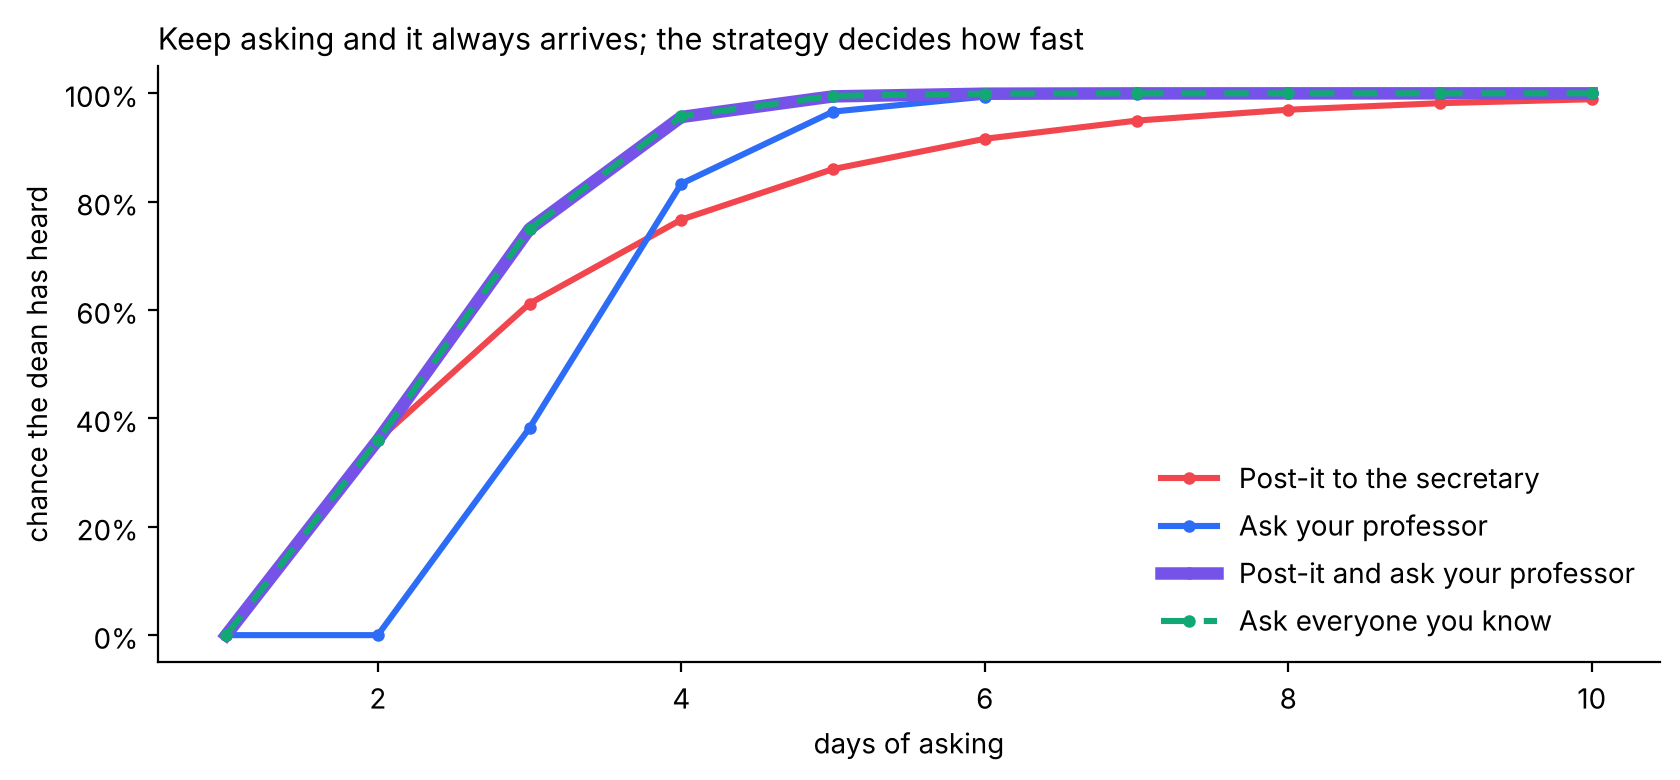

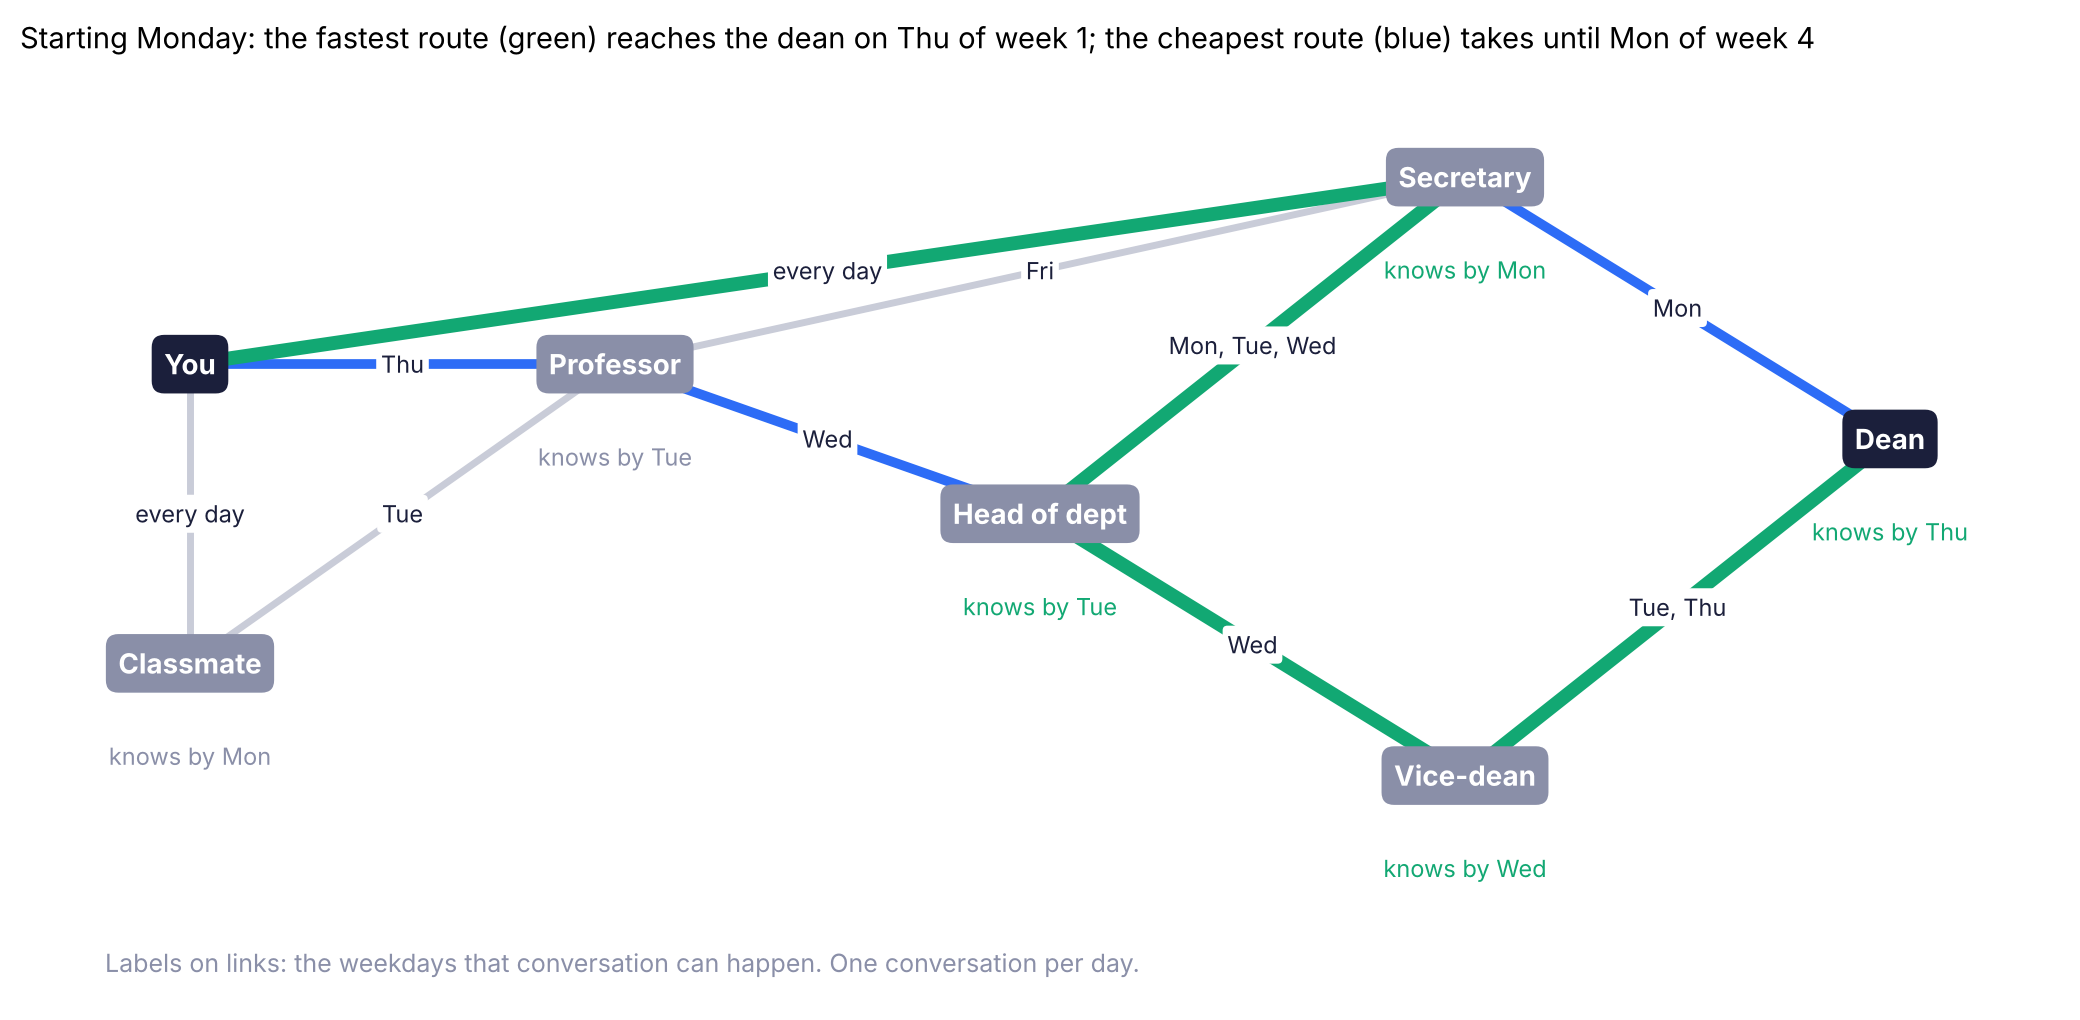

In [7]:
print("A. Asking every day until it arrives (exact Markov chain, no schedules):")
curves = {name: arrival_distribution(asks) for name, asks in STRATEGIES.items()}
for name, h in curves.items():
    print(f"   {name:32s} expected {expected_days(h):4.1f} days; "
          f"by day 3: {h[2]:4.0%}; by day 5: {h[4]:4.0%}")

print("\nB. With weekly schedules (no failures), starting Monday:")
arrival, before = earliest_arrival()
fastest = route_to(before)
cheapest = ["You", "Professor", "Head of dept", "Secretary", "Dean"]
print(f"   Fastest route: {' -> '.join(fastest)}, arrives {day_name(arrival['Dean'])}")
for name, r in [("Cheapest route (Dijkstra on costs)", cheapest),
                ("Post-it, then the diary meeting", ["You", "Secretary", "Dean"]),
                ("Via the vice-dean", ["You", "Professor", "Head of dept", "Vice-dean", "Dean"])]:
    print(f"   {name:36s} {' -> '.join(r)}: arrives {day_name(follow_route(r))}")
later, _ = earliest_arrival(start_day=3)
print(f"   Starting on Thursday instead, the earliest arrival is {day_name(later['Dean'])}")

print("\nC. Schedules and probabilities together (20,000 simulated weeks):")
deadlines = {"by Friday of week 1": 4, "by Friday of week 2": 11, "by Friday of week 3": 18}
for name, asks in STRATEGIES.items():
    res = simulate(asks, list(deadlines.values()))
    print(f"   {name:32s} " + "; ".join(f"{k}: {res[v]:.0%}" for k, v in deadlines.items()))

draw_timing_curves(curves, path="dean_fig4_keep_asking.png")
draw_temporal(arrival, fastest, cheapest, path="dean_fig5_timetable.png")
print("\nSaved dean_fig4_keep_asking.png and dean_fig5_timetable.png")